# 16. Write a python program to perform frequency domain filtering using Ideal, Butterworth, and Gaussian low-pass/high-pass filters.

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [43]:
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)
row, col = img.shape

In [44]:
F = np.fft.fftshift(np.fft.fft2(img))
u, v = np.meshgrid(np.arange(row), np.arange(col), indexing='ij')
D = np.sqrt((u - row / 2) ** 2 + (v - col / 2) ** 2)
D

array([[110.82531299, 110.08292329, 109.34463864, ..., 108.61054277,
        109.34463864, 110.08292329],
       [110.16011075, 109.41320761, 108.67037315, ..., 107.93169136,
        108.67037315, 109.41320761],
       [109.5       , 108.74856321, 108.0011574 , ..., 107.25786684,
        108.0011574 , 108.74856321],
       ...,
       [108.84507338, 108.08908363, 107.33708586, ..., 106.58916455,
        107.33708586, 108.08908363],
       [109.5       , 108.74856321, 108.0011574 , ..., 107.25786684,
        108.0011574 , 108.74856321],
       [110.16011075, 109.41320761, 108.67037315, ..., 107.93169136,
        108.67037315, 109.41320761]], shape=(148, 165))

In [45]:
D0 = 50
n = 2

In [46]:
# Filter
ILPF = np.zeros(img.shape)
ILPF[D <= D0] = 1

BLPF = 1 / (1 + (D / D0) ** (2 * n))

GLPF = np.exp(- (D**2) / (2 * D0**2))

In [47]:
def apply_filter(F, H):
    G = F * H
    result = np.fft.ifft2(np.fft.ifftshift(G))
    return np.clip(np.real(result), 0, 255)

In [48]:
idea_low_img = apply_filter(ILPF, F)
butterworth_low_img = apply_filter(BLPF, F)
gaussian_low_img = apply_filter(GLPF, F)

idea_high_img = apply_filter(1 - ILPF, F)
butterworth_high_img = apply_filter(1 - BLPF, F)
gaussian_high_img = apply_filter(1 - GLPF, F)

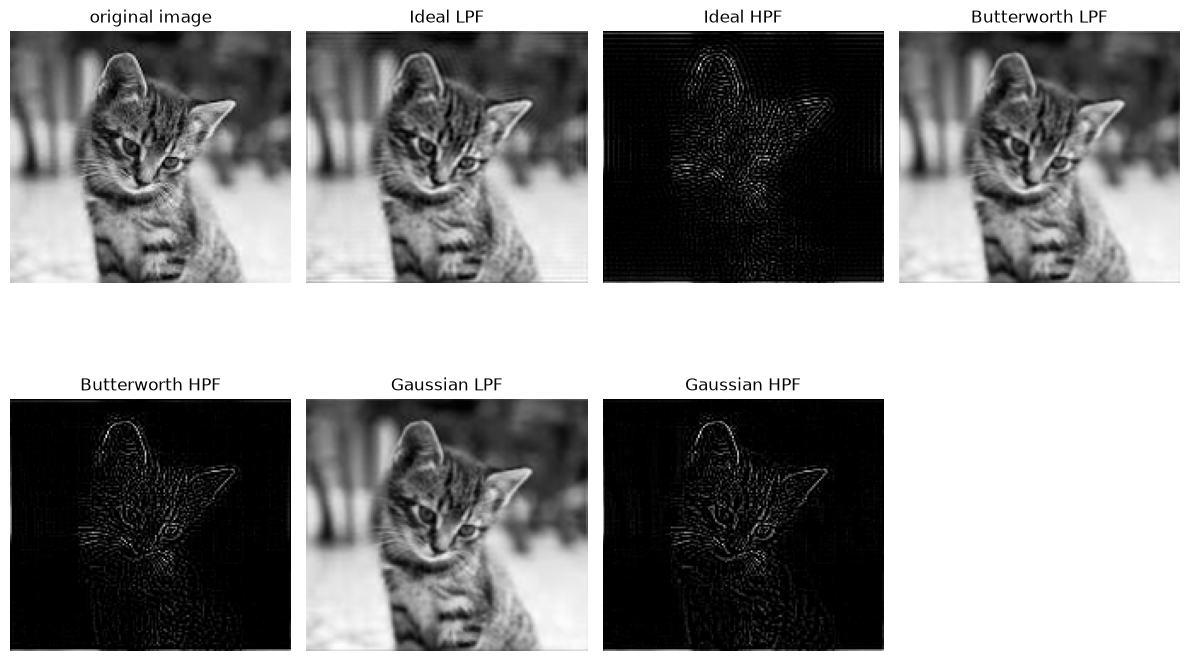

In [49]:
imgs = [img, idea_low_img, idea_high_img, butterworth_low_img, butterworth_high_img, gaussian_low_img, gaussian_high_img]
titles = ["original image", 'Ideal LPF', 'Ideal HPF', 'Butterworth LPF', 'Butterworth HPF', 'Gaussian LPF', 'Gaussian HPF']

plt.figure(figsize=(12, 8))

for i in range(7):
    plt.subplot(2, 4, i+1)
    plt.imshow(imgs[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()